# Phase 3: Exploratory Data Analysis (EDA)

**What:** Look at the data with charts and tables to find patterns in readmissions.

**Why:** I need to understand the data before any modelling. EDA shows problems like class imbalance and features that are strongly linked.

## Setup

**What:** Import the libraries and set the file paths.

**Why:** Keeping them at the top makes them easy to change.

In [7]:
import numpy as np # numbers and np.select
import pandas as pd # tables
import matplotlib.pyplot as plt # charts
import seaborn as sns # nice charts

ENRICHED = '../data/processed/02_enriched.csv'   # Phase 2 output
ID_MAPPING = '../data/raw/IDs_mapping.csv'       # ID names file

sns.set_theme(style='whitegrid') # clean chart style

## Loading the Data and Making the Target

**What:** Load `02_enriched.csv` and make a new column `readmit_30` (1 = readmitted within 30 days, 0 = not).

**Why:** With 0 and 1, the average of `readmit_30` is the readmission rate. I use this rate for every comparison. `keep_default_na=False` keeps `'None'` as a real value.

In [8]:
# Keep text 'None', treat empty cells as NaN
df = pd.read_csv(ENRICHED, keep_default_na=False, na_values=[''], low_memory=False)
print(df.shape)

# Target: 1 if readmitted within 30 days, else 0
df['readmit_30'] = (df['readmitted'] == '<30').astype(int)

(100114, 50)


## Adding Names to the ID Columns

**What:** Add `admission_type` and `admission_source` name columns using `IDs_mapping.csv`.

**Why:** The brief (spec 3.3) asks for names on the ID columns, because numbers like 1 or 7 mean nothing. The discharge names are added later in section 4.4.

In [9]:
def load_mapping(table_name):
    """Read one table (e.g. 'admission_type_id') from IDs_mapping.csv."""
    mapping, in_table = {}, False
    with open(ID_MAPPING, encoding='utf-8-sig') as file:
        for line in file:
            code, _, description = line.strip().partition(',')
            if code == table_name: # header of the table we want
                in_table = True
            elif code.endswith('_id'): # header of another table
                in_table = False
            elif in_table and code.isdigit(): # a row of our table
                mapping[int(code)] = description.strip().strip('"')
    return mapping


# Add readable names for the two ID columns not yet mapped (spec 3.3)
for id_col, name_col in [('admission_type_id', 'admission_type'),
                         ('admission_source_id', 'admission_source')]:
    df[name_col] = df[id_col].map(load_mapping(id_col))

df[['admission_type', 'admission_source']].isna().mean()   # any unmapped IDs?

admission_type      0.0
admission_source    0.0
dtype: float64

## 1. Readmission Outcomes

**What:** Count plot of `readmitted` (NO, >30, <30), with the % of each.

**Why:** Hospitals are penalised for the `<30` group (HRRP). I need to know how small it is, because that changes how I compare results.

readmitted
NO     53.2
>30    35.5
<30    11.3
Name: proportion, dtype: float64


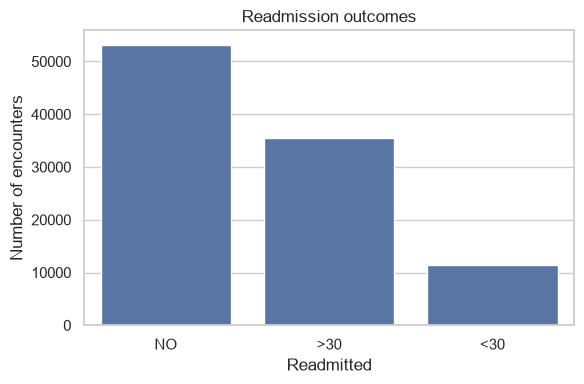

In [10]:
# Perecentage of each outcome
print(df['readmitted'].value_counts(normalize=True).mul(100).round(1))

# Count plot in a fixed order
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='readmitted', order=['NO', '>30', '<30'])
plt.title('Readmission outcomes')
plt.xlabel('Readmitted')
plt.ylabel('Number of encounters')
plt.tight_layout()
plt.show()

**Insight:** The `<30` group is a minority: 11.3%, compared with 53.2% for `NO` and 35.5% for `>30`. This means raw counts and accuracy can mislead (always guessing "not readmitted" would look accurate). So I compare **rates** between groups, and a later model must handle the imbalance.

## 2.1 Age Distribution

**What:** Count plot of age groups, and the share of patients aged 60 or older.

**Why:** To check if diabetes in this data mainly affects older people. This tells me who the results are about.

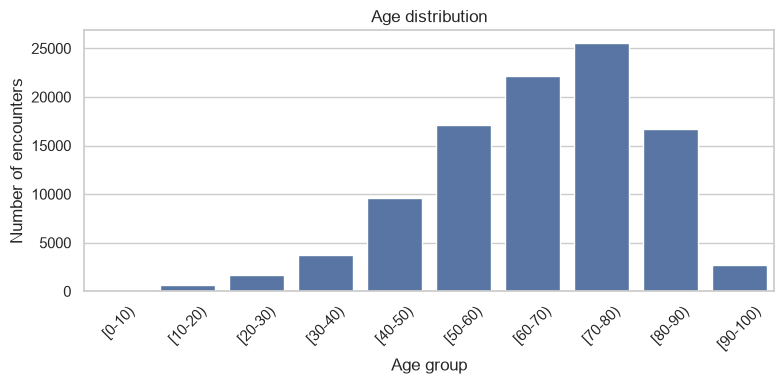

Share aged 60+: 67.0%


In [11]:
# Age groups in order: [0-10) ... [90-100)
age_order = sorted(df['age'].unique())

plt.figure(figsize=(8,4))
sns.countplot(data=df, x='age', order=age_order)
plt.title('Age distribution')
plt.xlabel('Age group')
plt.ylabel('Number of encounters')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Share of patients aged 60 or older
elderly = ['[60-70)', '[70-80)', '[80-90)', '[90-100)']
print(f"Share aged 60+: {df['age'].isin(elderly).mean():.1%}")

**Insight:** About 67% of encounters are patients aged 60 or older, and the biggest age group is 70-80. So diabetes hospital visits here are mostly elderly patients, and the results mainly describe older adults.

## 2.2 Readmission by Race and Gender

**What:** Grouped bar chart of the 30-day readmission rate for each race and gender, with the number of patients.

**Why:** To see if some groups are readmitted more, which could mean unequal care. I print the counts because rates from small groups are not reliable. Missing race rows are skipped, and the few `Unknown/Invalid` gender rows are removed.

              race  gender   mean  count  rate_pct
0  AfricanAmerican  Female  0.113  11531    11.274
1  AfricanAmerican    Male  0.116   7357    11.622
2            Asian  Female  0.076    316     7.595
3            Asian    Male  0.130    316    12.975
4        Caucasian  Female  0.117  39067    11.672
5        Caucasian    Male  0.113  35778    11.269
6         Hispanic  Female  0.092   1090     9.174
7         Hispanic    Male  0.120    934    11.991
8            Other  Female  0.104    738    10.434
9            Other    Male  0.091    747     9.103


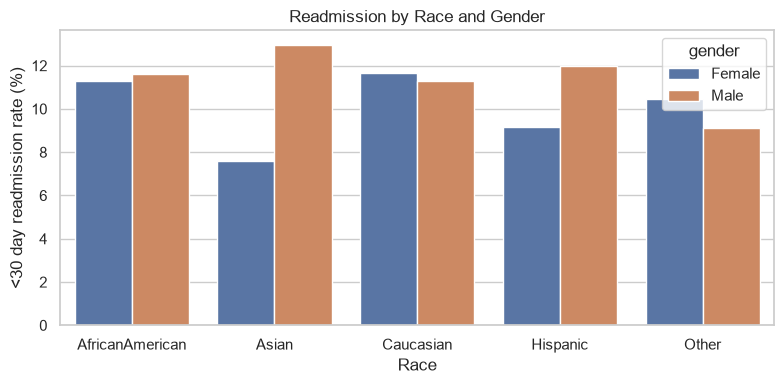

In [12]:
# Keep only Male / Female rows
plot_df = df[df['gender'].isin(['Male', 'Female'])]

# Readmission rate and patient count for each race + gender group
race_gender = (plot_df.groupby(['race', 'gender'])['readmit_30']
               .agg(['mean', 'count']).reset_index())

race_gender['rate_pct'] = race_gender['mean'] * 100
print(race_gender.round(3))

# Grouped bar chart
plt.figure(figsize=(8,4))
sns.barplot(data=race_gender, x='race', y='rate_pct', hue='gender')
plt.title('Readmission by Race and Gender')
plt.xlabel('Race')
plt.ylabel('<30 day readmission rate (%)')
plt.tight_layout()
plt.show()

 **Insight:** In the two big groups (Caucasian and African American) the rates are very close for both genders (about 11-12%), so no clear gap shows up. The biggest gaps are in small groups: Asian (7.6% vs 13.0%, only 316 patients each) and Hispanic (9.2% vs 12.0%). These could easily be chance, so I cannot say there is unequal care from this data.

##  3.1 Insulin vs Oral vs No Medication

 **What:** Make 4 groups: Insulin only, Oral only, Insulin + oral, No medication. Compare the readmission rate of each. "Oral" means one or more of the 22 oral drug columns.

 **Why:** To check if needing insulin goes with higher risk. Some patients take both, so "Insulin + oral" is its own group and nobody is counted twice.

  medication_group   mean  count  rate_pct
0   Insulin + oral  0.112  23232    11.196
1     Insulin only  0.132  30202    13.244
2    No medication  0.098  22842     9.833
3        Oral only  0.105  23838    10.529


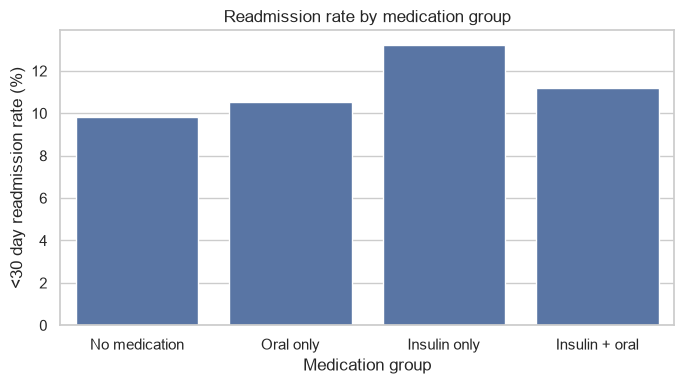

In [14]:
# The 22 oral medication columns
oral_columns = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide',
    'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone',
]

on_insulin = df['insulin'] != 'No' # any insulin
on_oral = (df[oral_columns] != 'No').any(axis=1) # one or more oral drugs

# Four groups (insulin and oral can overlap)
df['medication_group'] = np.select(
    [on_insulin & on_oral, on_insulin, on_oral],
    ['Insulin + oral', 'Insulin only', 'Oral only'],
    default='No medication')

# Readmission rate and patient count per group
med = df.groupby('medication_group')['readmit_30'].agg(['mean', 'count']).reset_index()
med['rate_pct'] = med['mean'] * 100
print(med.round(3))

plt.figure(figsize=(7, 4))
sns.barplot(data=med, x='medication_group', y='rate_pct',
            order=['No medication', 'Oral only', 'Insulin only', 'Insulin + oral'])
plt.title('Readmission rate by medication group')
plt.xlabel('Medication group')
plt.ylabel('<30 day readmission rate (%)')
plt.tight_layout()
plt.show()

 **Insight:** Insulin only has the highest rate (13.2%) and No medication the lowest (9.8%). So patients who need insulin are readmitted more, which may mean they are sicker. One surprise: Insulin + oral (11.2%) is lower than Insulin only. These patients may be more stable, but I cannot prove that. This is a link, not a cause: sicker patients need insulin more, so insulin may not be the reason.

##  3.2 Medication Change

 **What:** Compare the readmission rate of patients whose medication was changed (`Ch`) with those whose medication was not (`No`).

 **Why:** A medicine change may mean the patient was unstable and hard to control, so it may go with more readmissions.

  change   mean  count  rate_pct
0     Ch  0.120  46443    11.967
1     No  0.108  53671    10.805


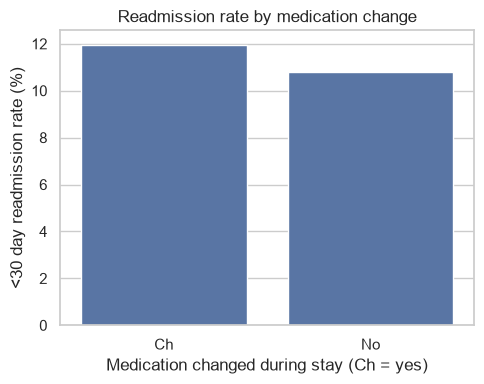

In [15]:
# Readmission rate and patient count for each 'change' value
change = df.groupby('change')['readmit_30'].agg(['mean', 'count']).reset_index()
change['rate_pct'] = change['mean'] * 100
print(change.round(3))

plt.figure(figsize=(5, 4))
sns.barplot(data=change, x='change', y='rate_pct')
plt.title('Readmission rate by medication change')
plt.xlabel('Medication changed during stay (Ch = yes)')
plt.ylabel('<30 day readmission rate (%)')
plt.tight_layout()
plt.show()

 **Insight:** Patients with a medication change have a rate of 12.0%, compared with 10.8% for no change. So a change goes with higher readmission, and these patients may be less stable. The gap is small, and again this shows a link only, not a cause.

##  4.1 Time in Hospital vs Lab Procedures

 **What:** Scatter plot with a trend line, and the correlation between the two columns.

 **Why:** To see if longer stays mean more lab tests in a straight-line way. I plot 5,000 random rows because too many points hide the pattern. The correlation uses all rows.

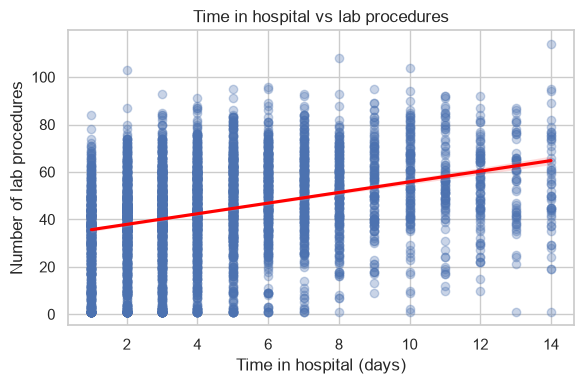

Correlation: 0.32


In [16]:
# Plot a randome sample of 5000 rows (too many points hide the pattern)
sample = df.sample(5000, random_state=42)

plt.figure(figsize=(6, 4))
sns.regplot(data=sample, x='time_in_hospital', y='num_lab_procedures',
            scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
plt.title('Time in hospital vs lab procedures')
plt.xlabel('Time in hospital (days)')
plt.ylabel('Number of lab procedures')
plt.tight_layout()
plt.show()

# Correlation on the full data
print(f"Correlation: {df['time_in_hospital'].corr(df['num_lab_procedures']):.2f}")

 **Insight:** The correlation is 0.32, a weak positive link. Patients who stay longer tend to have more lab tests, but the points are spread out, so time in hospital explains only a small part.